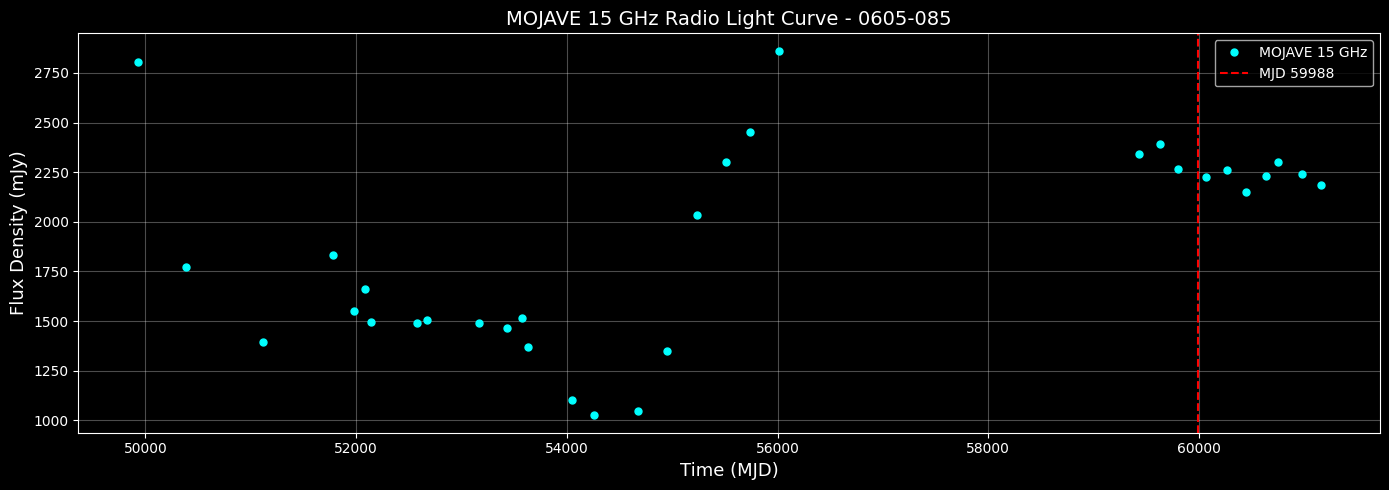

Number of observations: 31
MJD range: 49926.0 - 61157.0


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. READ MOJAVE DATA FROM TXT FILE
# ==========================================

df = pd.read_csv("MOJAVEsource.txt", sep="\t")

# Clean column names
df.columns = df.columns.str.strip()

# ==========================================
# 2. CONVERT DATE TO MJD
# ==========================================

df["Date"] = pd.to_datetime(df["Date"])

df["MJD"] = (
    df["Date"].apply(lambda x: x.to_julian_date())
    - 2400000.5
)

# Convert flux to numeric
df["Flux Density (mJy)"] = pd.to_numeric(
    df["Flux Density (mJy)"],
    errors="coerce"
)

# Remove invalid values
df = df.dropna(subset=["MJD", "Flux Density (mJy)"])

# Sort by time
df = df.sort_values("MJD")

# ==========================================
# 3. PLOT MOJAVE LIGHT CURVE
# ==========================================

plt.figure(figsize=(14, 5))

plt.plot(
    df["MJD"],
    df["Flux Density (mJy)"],
    "o",
    color="cyan",
    markersize=5,
    label="MOJAVE 15 GHz"
)

# Vertical dashed red line at MJD 59988
plt.axvline(
    x=59988,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="MJD 59988"
)

plt.xlabel("Time (MJD)", fontsize=13)
plt.ylabel("Flux Density (mJy)", fontsize=13)
plt.title("MOJAVE 15 GHz Radio Light Curve - 0605-085", fontsize=14)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 4. PRINT INFORMATION
# ==========================================

print("Number of observations:", len(df))
print("MJD range:", df["MJD"].min(), "-", df["MJD"].max())